# CommerceGuard · Episode 2
## From one model to a risk system
1. **Customer voice** (Bangladesh): Daraz + Pickaboo reviews, Bangla and English. Who is about to become an unhappy customer?
2. **Order risk** (a cash-on-delivery market): will this order be cancelled? refunded?
3. **Delivery risk**: Episode 1 model (Olist).
4. **CommerceGuard engine**: one ranked review list from the risks.

Data: Rashid et al. (2023), *A Multilabel Multiclass Sentiment and Emotion Dataset from Bangladeshi E-Commerce Reviews*, Mendeley Data, CC BY 4.0 · Pakistan's Largest E-Commerce Dataset (Kaggle, 2016–2018).

## Setup

In [1]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, precision_recall_curve
pd.set_option("display.width", 140); sns.set_theme(style="whitegrid")
SEED = 42
RAW = "../data/raw_ep2/"
FIG = "../reports/figures/ep2_"

# Model 1 · Customer voice (Bangladesh)

In [2]:
r = pd.read_csv(RAW + "bd_reviews.csv")
print(r.shape)
print(r["Emotion"].value_counts().to_dict())
print(r["Data Source"].value_counts().to_dict())
bangla = r["Review"].astype(str).str.contains(r"[\u0980-\u09FF]")
print(f"Bangla reviews: {bangla.mean():.1%}   negative: {(r['Sentiment'] == 'Negative').mean():.1%}")

(78130, 7)
{'Happy': 46635, 'Love': 20633, 'Sadness': 6533, 'Anger': 3171, 'Fear': 1158}
{'Daraz': 72732, 'Pickaboo': 5398}
Bangla reviews: 37.1%   negative: 13.9%


In [3]:
# Trap 1: the same review text appears many times. Keep one copy.
print("duplicate texts:", r["Review"].duplicated().sum())
r = r.drop_duplicates("Review").reset_index(drop=True)
r["y"] = (r["Sentiment"] == "Negative").astype(int)
print("after de-duplication:", len(r), f"negative {r['y'].mean():.1%}")

duplicate texts: 13983
after de-duplication: 64147 negative 16.3%


In [4]:
# What do unhappy Bangladeshi customers talk about? (keyword share, Bangla + English)
topics = {
    "delivery / late": r"deliver|late|ডেলিভারি|দেরি|দেরিতে|পৌঁছ",
    "fake / not original": r"fake|duplicate|copy|নকল|ফেক|ডুপ্লিকেট|অরিজিনাল না",
    "damaged / broken": r"damage|broken|ভাঙ্গা|ভাঙা|নষ্ট|ড্যামেজ",
    "wrong product": r"wrong|different|ভুল|অন্য প্রোডাক্ট|ভিন্ন",
    "return / refund": r"return|refund|রিটার্ন|ফেরত",
}
txt = r["Review"].astype(str).str.lower()
share = pd.DataFrame({t: [txt[r.y == 1].str.contains(p).mean(), txt[r.y == 0].str.contains(p).mean()] for t, p in topics.items()},
                     index=["unhappy", "happy"]).T.round(3)
share["x more often"] = (share["unhappy"] / share["happy"].clip(lower=1e-3)).round(1)
share.sort_values("unhappy", ascending=False)

,unhappy,happy,x more often
delivery / late,0.070,0.106,0.7
damaged / broken,0.060,0.005,12.0
return / refund,0.045,0.003,15.0
fake / not original,0.019,0.005,3.8
wrong product,0.019,0.004,4.8


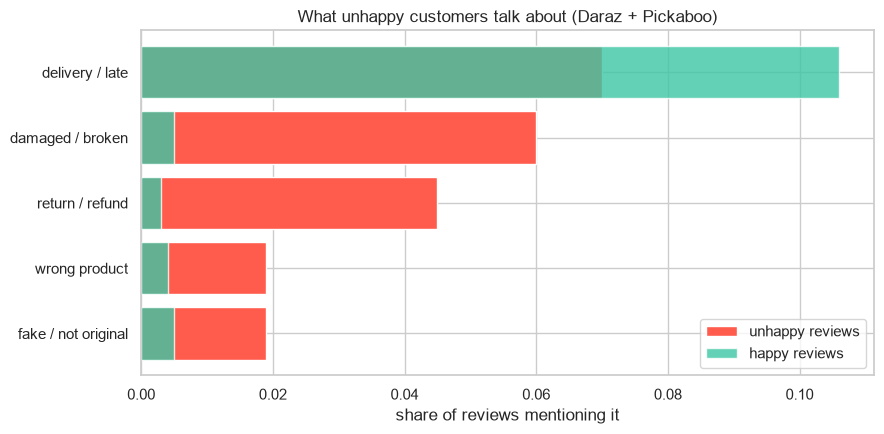

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
s = share.sort_values("unhappy")
ax.barh(s.index, s["unhappy"], color="#FF5C4D", label="unhappy reviews")
ax.barh(s.index, s["happy"], color="#3CC6A4", alpha=.8, label="happy reviews")
ax.set(xlabel="share of reviews mentioning it", title="What unhappy customers talk about (Daraz + Pickaboo)")
ax.legend(); fig.tight_layout(); fig.savefig(FIG + "topics.png", dpi=200)

In [6]:
# Trap 2: reviews of the same product share words and labels. Split by PRODUCT, never by row.
from sklearn.model_selection import GroupShuffleSplit
g = r["Product Name"].astype(str)
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
tr_i, rest_i = next(gss.split(r, groups=g))
rest = r.iloc[rest_i]
va_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED).split(rest, groups=rest["Product Name"].astype(str)))
rtr, rva, rte = r.iloc[tr_i], rest.iloc[va_i], rest.iloc[te_i]
assert not set(rtr["Product Name"]) & set(rte["Product Name"]), "product leak"
for n, d in [("train", rtr), ("val", rva), ("test", rte)]:
    print(f"{n:5s} {len(d):6,} reviews  {d['Product Name'].nunique():5,} products  negative {d['y'].mean():.1%}")

train 43,773 reviews  1,652 products  negative 16.6%
val    9,691 reviews    354 products  negative 14.2%
test  10,683 reviews    355 products  negative 17.0%


In [7]:
# Text only. The star rating is NOT a feature: at prediction time (a chat message) there is no rating.
from sklearn.pipeline import make_pipeline, make_union
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
vec = lambda: make_union(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=300_000),
                         TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b"))
voice_models = {
    "Naive Bayes (baseline)": make_pipeline(vec(), ComplementNB()),
    "Logistic Regression": make_pipeline(vec(), LogisticRegression(C=4, max_iter=3000, class_weight="balanced")),
}
rows = [{"model": "random guess", "PR-AUC": rva["y"].mean(), "ROC-AUC": .5}]
for name, m in voice_models.items():
    m.fit(rtr["Review"].astype(str), rtr["y"])
    s = m.predict_proba(rva["Review"].astype(str))[:, 1]
    rows.append({"model": name, "PR-AUC": average_precision_score(rva["y"], s), "ROC-AUC": roc_auc_score(rva["y"], s)})
pd.DataFrame(rows).round(3)

,model,PR-AUC,ROC-AUC
0,random guess,0.142,0.500
1,Naive Bayes (baseline),0.702,0.923
2,Logistic Regression,0.799,0.960


In [8]:
voice = voice_models["Logistic Regression"]
sva = voice.predict_proba(rva["Review"].astype(str))[:, 1]
th = max(np.linspace(.05, .95, 91), key=lambda t: f1_score(rva["y"], sva >= t))   # threshold chosen on validation
ste = voice.predict_proba(rte["Review"].astype(str))[:, 1]
bn_te = rte["Review"].astype(str).str.contains(r"[\u0980-\u09FF]")
print(f"threshold {th:.2f} (chosen on validation)")
print(f"TEST  PR-AUC {average_precision_score(rte['y'], ste):.3f}   ROC-AUC {roc_auc_score(rte['y'], ste):.3f}   F1 {f1_score(rte['y'], ste >= th):.3f}   random PR-AUC {rte['y'].mean():.3f}")
for name, mask in [("Bangla", bn_te), ("English", ~bn_te)]:
    print(f"  {name:8s} n={mask.sum():5,}  PR-AUC {average_precision_score(rte['y'][mask], ste[mask]):.3f}")

threshold 0.58 (chosen on validation)
TEST  PR-AUC 0.821   ROC-AUC 0.959   F1 0.774   random PR-AUC 0.170
  Bangla   n=4,323  PR-AUC 0.859
  English  n=6,360  PR-AUC 0.774


In [9]:
# Which words push a message toward 'unhappy'? (word part of the model)
lr = voice.named_steps["logisticregression"]; fu = voice.named_steps["featureunion"]
names = np.concatenate([fu.transformer_list[0][1].get_feature_names_out(), fu.transformer_list[1][1].get_feature_names_out()])
coef = lr.coef_[0]; wmask = np.arange(len(names)) >= len(fu.transformer_list[0][1].get_feature_names_out())
top = pd.Series(coef[wmask], index=names[wmask]).sort_values()
print("most UNHAPPY words:", ", ".join(top.tail(15).index[::-1]))
print("most HAPPY words:  ", ", ".join(top.head(15).index))

most UNHAPPY words: ল ন, not, valo na, very bad, বই খ, t, bad product, not good, no good, valo satisfied, na, awesome quality, high price, not recommended, low quality
most HAPPY words:   not bad, kharap na, প ন, good, ভ ল, ন সমস, best, nice, বই ভ, ব ভ, valo, ক ভ, cute, excellent, very good


# Model 2 · Order risk in a cash-on-delivery market

In [10]:
p = pd.read_csv(RAW + "Pakistan Largest Ecommerce Dataset.csv", low_memory=False).dropna(how="all")
p = p.rename(columns={"Customer ID": "customer_id", "Customer Since": "customer_since"})
print(p.shape)
print(p["status"].value_counts().head(12).to_dict())

(584524, 26)
{'complete': 233685, 'canceled': 201249, 'received': 77290, 'order_refunded': 59529, 'refund': 8050, 'cod': 2859, 'paid': 1159, 'closed': 494, 'payment_review': 57, 'pending': 48, 'processing': 33, 'holded': 31}


In [11]:
# Clean outcomes only. "cod", "paid", "pending"... are not outcomes (the column mixes fields): drop them.
OUT = {"complete": "ok", "received": "ok", "closed": "ok", "canceled": "cancel", "order_refunded": "refund", "refund": "refund"}
p = p[p["status"].isin(OUT)].copy()
p["outcome"] = p["status"].map(OUT)
p["date"] = pd.to_datetime(p["created_at"], format="%m/%d/%Y", errors="coerce")
p = p.dropna(subset=["date", "customer_id"]).sort_values(["date", "increment_id"]).reset_index(drop=True)
p["y_cancel"] = (p["outcome"] == "cancel").astype(int)
p["y_refund"] = (p["outcome"] == "refund").astype(int)
p["is_cod"] = p["payment_method"].isin(["cod", "cashatdoorstep"]).astype(int)
print(len(p), p["date"].min().date(), "to", p["date"].max().date())
print(p["outcome"].value_counts(normalize=True).round(3).to_dict())

580286 2016-07-01 to 2018-08-28
{'ok': 0.537, 'cancel': 0.347, 'refund': 0.116}


                   items  cancelled  refunded
is_cod                                       
Cash on delivery  269773      0.081     0.202
Paid online       310513      0.578     0.042


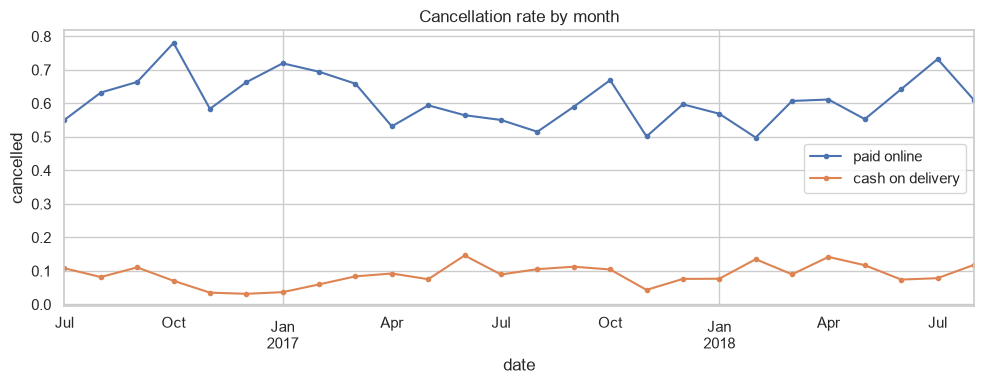

In [12]:
# The cash-on-delivery question, in one table
tab = p.groupby(p["is_cod"].map({1: "Cash on delivery", 0: "Paid online"})).agg(
    items=("outcome", "size"), cancelled=("y_cancel", "mean"), refunded=("y_refund", "mean")).round(3)
print(tab)
m = p.groupby([p["date"].dt.to_period("M"), "is_cod"])["y_cancel"].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 4)); m.plot(ax=ax, marker=".")
ax.set(title="Cancellation rate by month", ylabel="cancelled"); ax.legend(["paid online", "cash on delivery"])
fig.tight_layout(); fig.savefig(FIG + "cancel_by_month.png", dpi=200)

In [13]:
# Customer history from the PAST only.
# Cancellations are known within days, so count orders from strictly earlier dates.
# Refunds can take weeks, so only count refunds on orders placed 30+ days earlier.
p["cust"] = p["customer_id"].astype(str)
day = p.groupby(["cust", "date"]).agg(n=("y_cancel", "size"), c=("y_cancel", "sum"), r=("y_refund", "sum")).reset_index()
day = day.sort_values(["cust", "date"])
for col in ["n", "c"]:
    day["prev_" + col] = day.groupby("cust")[col].cumsum() - day[col]          # strictly earlier days
day["cum_r"] = day.groupby("cust")["r"].cumsum()
day["cum_n"] = day.groupby("cust")["n"].cumsum()
p = p.merge(day[["cust", "date", "prev_n", "prev_c"]], on=["cust", "date"], how="left")
lag = day[["cust", "date", "cum_r", "cum_n"]].assign(date=lambda d: d["date"] + pd.Timedelta(days=30)).sort_values("date")
p = pd.merge_asof(p.sort_values("date"), lag.rename(columns={"cum_r": "old_r", "cum_n": "old_n"}), on="date", by="cust",
                  allow_exact_matches=True, direction="backward").sort_values(["date", "increment_id"]).reset_index(drop=True)
p[["old_r", "old_n"]] = p[["old_r", "old_n"]].fillna(0)
p["prev_cancel_rate"] = (p["prev_c"] + p["y_cancel"].mean() * 3) / (p["prev_n"] + 3)
p["old_refund_rate"] = (p["old_r"] + p["y_refund"].mean() * 3) / (p["old_n"] + 3)
p["same_day_items"] = p.groupby(["cust", "date"]).cumcount()                       # items earlier the same day (by order number)
since = pd.to_datetime(p["customer_since"], format="%Y-%m", errors="coerce")
p["tenure_months"] = ((p["date"] - since).dt.days / 30.4).clip(lower=0)
p["month"], p["weekday"], p["day"] = p["date"].dt.month, p["date"].dt.weekday, p["date"].dt.day
p["discount_ratio"] = (p["discount_amount"] / p["grand_total"].replace(0, np.nan)).clip(0, 1).fillna(0)
p["log_total"] = np.log1p(p["grand_total"].clip(lower=0))
print(p[["prev_n", "prev_cancel_rate", "old_refund_rate", "same_day_items", "tenure_months"]].describe().round(2).T[["mean", "50%", "max"]])

                   mean   50%      max
prev_n            51.02  2.00  2507.00
prev_cancel_rate   0.34  0.35     0.99
old_refund_rate    0.12  0.12     0.98
same_day_items     3.49  1.00   221.00
tenure_months      3.46  0.92    25.89


/var/folders/d7/d_t10ccj3050z2gr_mfh2w880000gn/T/ipykernel_72027/1687655278.py:21: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  p["month"], p["weekday"], p["day"] = p["date"].dt.month, p["date"].dt.weekday, p["date"].dt.day


In [14]:
LEAKY = ["status", "outcome", "BI Status", "Working Date", " MV ", "y_cancel", "y_refund", "increment_id"]
NUM = ["price", "qty_ordered", "log_total", "discount_ratio", "is_cod", "prev_n", "prev_cancel_rate", "old_refund_rate",
       "same_day_items", "tenure_months", "month", "weekday", "day"]
CAT = ["category_name_1", "payment_method"]
FEAT = NUM + CAT
assert not set(FEAT) & set(LEAKY), "leaky column"
for c in CAT:
    p[c] = p[c].fillna("unknown").astype("category")
n = len(p); a, b = int(n * .70), int(n * .85)
ptr, pva, pte = p.iloc[:a], p.iloc[a:b], p.iloc[b:]
for nm, d in [("train", ptr), ("val", pva), ("test", pte)]:
    print(f"{nm:5s} {len(d):7,}  {d['date'].min():%Y-%m-%d} to {d['date'].max():%Y-%m-%d}  cancel {d['y_cancel'].mean():.1%}  refund {d['y_refund'].mean():.1%}")

train 406,200  2016-07-01 to 2017-11-30  cancel 31.8%  refund 12.5%
val    87,043  2017-11-30 to 2018-03-27  cancel 37.3%  refund 10.1%
test   87,043  2018-03-27 to 2018-08-28  cancel 45.5%  refund 9.3%


In [15]:
import lightgbm as lgb
def train(target, Xtr, ytr, Xva, yva):
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.04, num_leaves=63, min_child_samples=100, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, random_state=SEED, verbose=-1)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="average_precision", callbacks=[lgb.early_stopping(150, verbose=False)])
    return m

base_rows, risk_models = [], {}
for tgt in ["y_cancel", "y_refund"]:
    if tgt == "y_refund":   # refund is only possible if the order was not cancelled
        tr_, va_ = ptr[ptr.y_cancel == 0], pva[pva.y_cancel == 0]
    else:
        tr_, va_ = ptr, pva
    lr_s = LogisticRegression(max_iter=2000, class_weight="balanced").fit(tr_[["is_cod", "prev_cancel_rate", "log_total"]], tr_[tgt]) \
        .predict_proba(va_[["is_cod", "prev_cancel_rate", "log_total"]])[:, 1]
    risk_models[tgt] = m = train(tgt, tr_[FEAT], tr_[tgt], va_[FEAT], va_[tgt])
    s = m.predict_proba(va_[FEAT])[:, 1]
    base_rows += [{"target": tgt, "model": "random", "PR-AUC": va_[tgt].mean()},
                  {"target": tgt, "model": "Logistic Regression (3 features)", "PR-AUC": average_precision_score(va_[tgt], lr_s)},
                  {"target": tgt, "model": f"LightGBM ({m.best_iteration_} trees)", "PR-AUC": average_precision_score(va_[tgt], s)}]
pd.DataFrame(base_rows).round(3)

/Users/zishan/Projects/CommerceGuard/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/Users/zishan/Projects/CommerceGuard/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,target,model,PR-AUC
0,y_cancel,random,0.373
1,y_cancel,Logistic Regression (3 features),0.637
2,y_cancel,LightGBM (75 trees),0.728
3,y_refund,random,0.161
4,y_refund,Logistic Regression (3 features),0.221
5,y_refund,LightGBM (69 trees),0.373


In [16]:
from sklearn.isotonic import IsotonicRegression
cal = {}
for tgt, m in risk_models.items():
    va_ = pva if tgt == "y_cancel" else pva[pva.y_cancel == 0]
    cal[tgt] = IsotonicRegression(out_of_bounds="clip").fit(m.predict_proba(va_[FEAT])[:, 1], va_[tgt])
final = []
for tgt, m in risk_models.items():
    te_ = pte if tgt == "y_cancel" else pte[pte.y_cancel == 0]
    s = cal[tgt].predict(m.predict_proba(te_[FEAT])[:, 1])
    k = int(len(s) * .10); top = np.argsort(-s)[:k]
    final.append({"target": tgt, "test rows": len(te_), "base rate": te_[tgt].mean(), "PR-AUC": average_precision_score(te_[tgt], s),
                  "ROC-AUC": roc_auc_score(te_[tgt], s), "precision@top10%": te_[tgt].iloc[top].mean(), "recall@top10%": te_[tgt].iloc[top].sum() / te_[tgt].sum()})
print("TEST (used once)")
pd.DataFrame(final).round(3)

TEST (used once)


,target,test rows,base rate,PR-AUC,ROC-AUC,precision@top10%,recall@top10%
0,y_cancel,87043,0.455,0.789,0.844,0.892,0.196
1,y_refund,47408,0.172,0.349,0.695,0.422,0.246


/Users/zishan/Projects/CommerceGuard/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/zishan/Projects/CommerceGuard/.venv/lib/python3.11/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


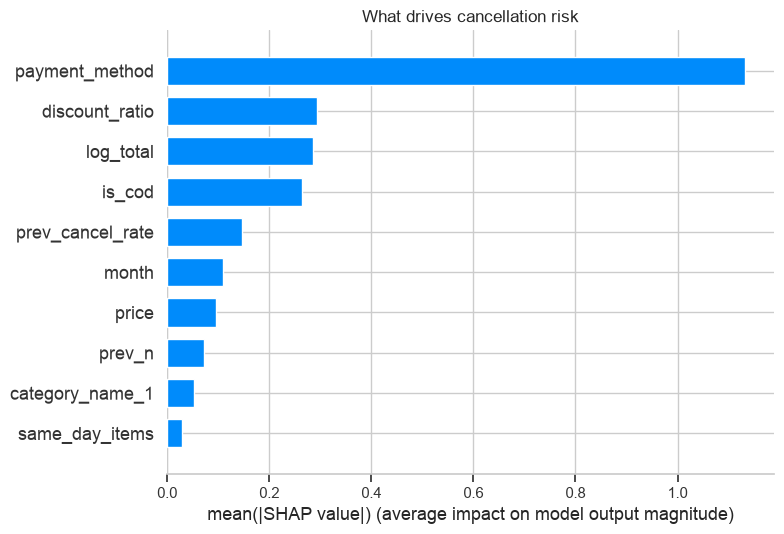

In [17]:
import shap
smp = pte[FEAT].sample(4000, random_state=SEED)
sv = shap.TreeExplainer(risk_models["y_cancel"]).shap_values(smp)
sv = sv[1] if isinstance(sv, list) else sv
plt.figure(); shap.summary_plot(sv, smp, plot_type="bar", max_display=10, show=False)
plt.title("What drives cancellation risk"); plt.tight_layout(); plt.savefig(FIG + "shap_cancel.png", dpi=200)

# CommerceGuard engine · one ranked list

review top 5% of items -> catches 36.8% of the loss
review top 10% of items -> catches 51.3% of the loss
review top 20% of items -> catches 64.9% of the loss


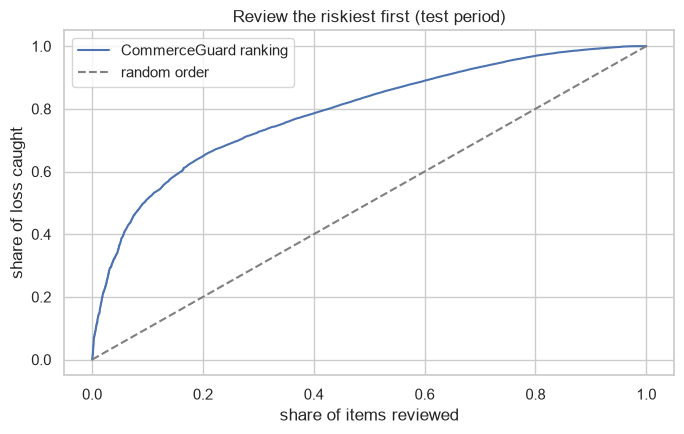

In [18]:
# Expected loss per order item = P(cancel) x handling cost + P(refund) x (refund cost). Costs are illustrative inputs, not data.
COST_CANCEL, COST_REFUND_SHARE = 150, 0.15   # Rs per cancelled item, 15% of value lost per refund
te = pte.copy()
te["p_cancel"] = cal["y_cancel"].predict(risk_models["y_cancel"].predict_proba(te[FEAT])[:, 1])
te["p_refund"] = cal["y_refund"].predict(risk_models["y_refund"].predict_proba(te[FEAT])[:, 1]) * (1 - te["p_cancel"])
te["expected_loss"] = te["p_cancel"] * COST_CANCEL + te["p_refund"] * te["grand_total"].clip(lower=0) * COST_REFUND_SHARE
te["actual_loss"] = te["y_cancel"] * COST_CANCEL + te["y_refund"] * te["grand_total"].clip(lower=0) * COST_REFUND_SHARE
order = te.sort_values("expected_loss", ascending=False)
cum = order["actual_loss"].cumsum() / order["actual_loss"].sum()
for q in [.05, .10, .20]:
    print(f"review top {q:.0%} of items -> catches {cum.iloc[int(len(cum) * q) - 1]:.1%} of the loss")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, len(cum) + 1) / len(cum), cum.values, label="CommerceGuard ranking")
ax.plot([0, 1], [0, 1], "--", c="gray", label="random order")
ax.set(xlabel="share of items reviewed", ylabel="share of loss caught", title="Review the riskiest first (test period)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG + "loss_curve.png", dpi=200)

In [19]:
# The chat from the video: real model scores for example messages (the messages are written for the demo).
chat = ["ভাই, অর্ডার করছি, ক্যাশ অন ডেলিভারি তো?",
        "৩ দিন হয়ে গেল, এখনো পণ্য পাইনি",
        "প্রোডাক্ট টা নকল মনে হচ্ছে, ছবির সাথে মিল নাই",
        "আমি রিটার্ন করবো, টাকা ফেরত চাই",
        "Thanks bhai, product ta khub valo hoise!"]
for m_ in chat:
    print(f"{voice.predict_proba([m_])[0, 1]:.0%}  unhappy  |  {m_}")

20%  unhappy  |  ভাই, অর্ডার করছি, ক্যাশ অন ডেলিভারি তো?
90%  unhappy  |  ৩ দিন হয়ে গেল, এখনো পণ্য পাইনি
95%  unhappy  |  প্রোডাক্ট টা নকল মনে হচ্ছে, ছবির সাথে মিল নাই
94%  unhappy  |  আমি রিটার্ন করবো, টাকা ফেরত চাই
0%  unhappy  |  Thanks bhai, product ta khub valo hoise!


## Summary
- Customer voice: text model on 64k unique Daraz + Pickaboo reviews, split by product.
- Order risk: cancellation + refund models on real COD-market orders, time split, history from the past only, test used once.
- Limits: reviews are a proxy for complaints, not returns; order data is Pakistan 2016–18, not Bangladesh; costs are illustrative.